# Zipfian Curvature and Semantic Drift Analysis

This notebook demonstrates the methodology for analyzing Zipf-Mandelbrot distribution parameters and their correlation with semantic drift in narrative text.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'pandas==2.2.2', 'scipy==1.16.3', 'matplotlib==3.10.0', 'loguru==0.7.3')

In [2]:
import json, math, re, sys, numpy as np
from collections import Counter
from pathlib import Path
from scipy import optimize, stats
from scipy.spatial.distance import cosine
import matplotlib.pyplot as plt
if not hasattr(np, "alltrue"): np.alltrue = np.all
if not hasattr(np, "sometrue"): np.sometrue = np.any
if not hasattr(np, "product"): np.product = np.prod
COLOURS = {
    "method": "#0173B2", "baseline": "#949494", "other_1": "#DE8F05", "other_2": "#029E73", "other_3": "#CC78BC", "other_4": "#CA9161", "other_5": "#56B4E9",
}
plt.rcParams.update({
    "font.family": "serif", "font.size": 11, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.grid.axis": "y", "axes.axisbelow": True, "axes.prop_cycle": plt.cycler(color=list(COLOURS.values())), "figure.constrained_layout.use": True, "figure.dpi": 120
})

Matplotlib is building the font cache; this may take a moment.


In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-624cdf-local-zipfian-curvature-as-narrative/main/round-1/experiment-1/demo/mini_demo_data.json"
import http.client, urllib.request
def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    except (OSError, ValueError, http.client.HTTPException):
        local = Path("mini_demo_data.json")
        if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")
data = load_data()

### Config

In [4]:
WINDOW_SIZE = 500
STRIDE = 100

### Results

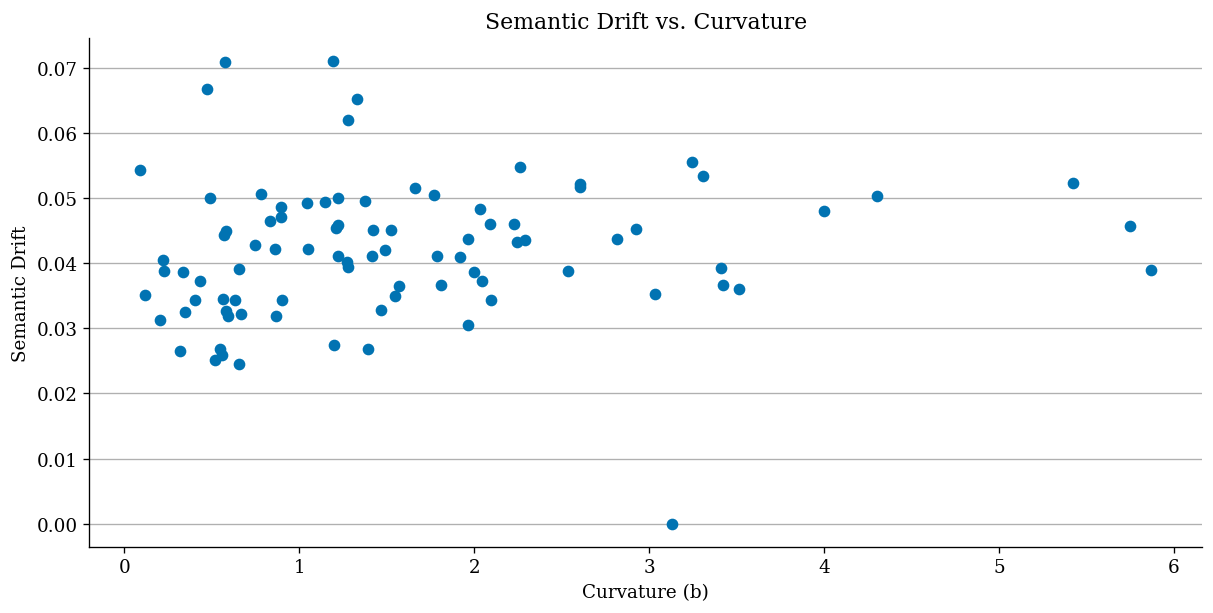

In [5]:
example = data['datasets'][0]['examples'][0]
results = json.loads(example['output'])
window_results = results['window_results']
drifts = [r['semantic_drift'] for r in window_results]
b_values = [r['b'] for r in window_results if r['b'] is not None]
drifts = drifts[:len(b_values)]
plt.figure(figsize=(10, 5))
plt.scatter(b_values, drifts, color=COLOURS['method'])
plt.xlabel('Curvature (b)')
plt.ylabel('Semantic Drift')
plt.title('Semantic Drift vs. Curvature')
plt.show()